Iteration 1/2000 | Leader: 442.478 | Best: 442.478
Iteration 100/2000 | Leader: 391.674 | Best: 391.674
Iteration 200/2000 | Leader: 391.674 | Best: 391.674
Iteration 300/2000 | Leader: 391.674 | Best: 391.674
Iteration 400/2000 | Leader: 391.674 | Best: 391.674
Iteration 500/2000 | Leader: 391.674 | Best: 391.674
Iteration 600/2000 | Leader: 391.674 | Best: 391.674
Iteration 700/2000 | Leader: 391.674 | Best: 391.674
Iteration 800/2000 | Leader: 391.674 | Best: 391.674
Iteration 900/2000 | Leader: 391.674 | Best: 391.674
Iteration 1000/2000 | Leader: 387.429 | Best: 387.429
Iteration 1100/2000 | Leader: 387.429 | Best: 387.429
Iteration 1200/2000 | Leader: 387.429 | Best: 387.429
Iteration 1300/2000 | Leader: 387.429 | Best: 387.429
Iteration 1400/2000 | Leader: 387.429 | Best: 387.429
Iteration 1500/2000 | Leader: 387.429 | Best: 387.429
Iteration 1600/2000 | Leader: 387.429 | Best: 387.429
Iteration 1700/2000 | Leader: 387.429 | Best: 387.429
Iteration 1800/2000 | Leader: 387.429 | 

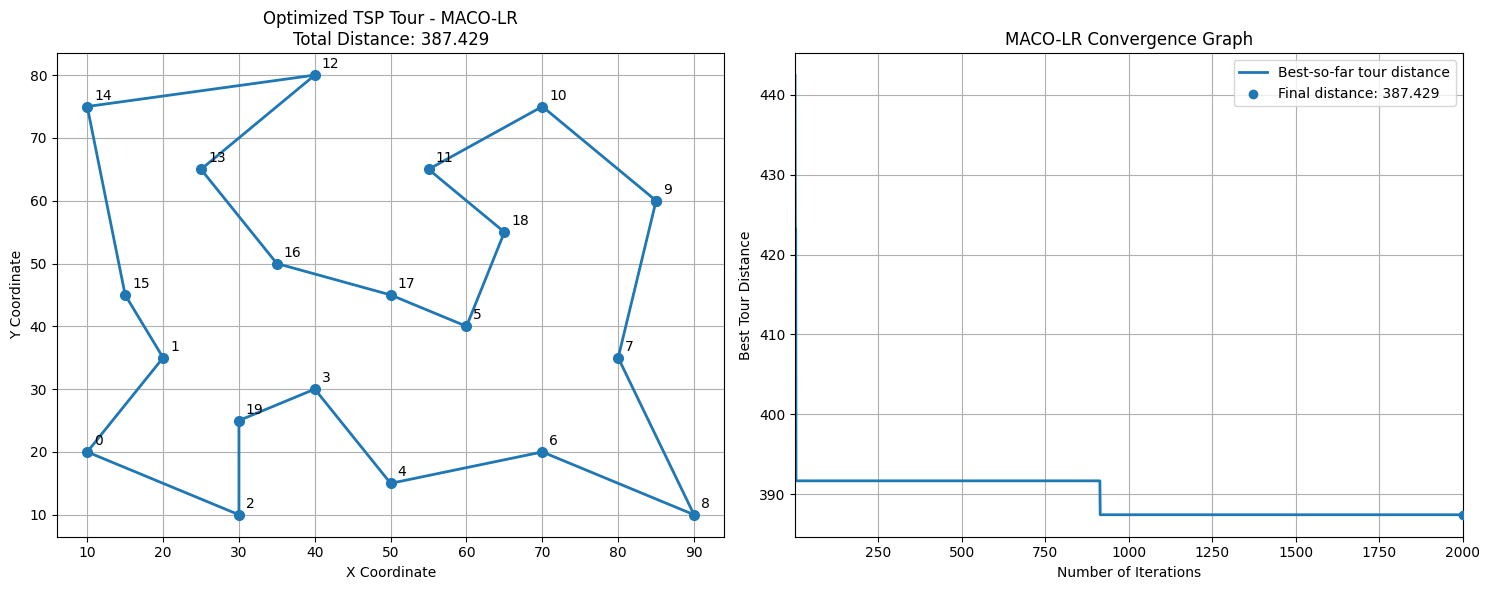

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------- CITY COORDINATES --------------------

CITIES = np.array([
    [10, 20], [20, 35], [30, 10], [40, 30], [50, 15],
    [60, 40], [70, 20], [80, 35], [90, 10], [85, 60],
    [70, 75], [55, 65], [40, 80], [25, 65], [10, 75],
    [15, 45], [35, 50], [50, 45], [65, 55], [30, 25]
], dtype=float)


# -------------------- PARAMETERS --------------------

NUM_ANTS = 100
MAX_ITERATIONS = 2000

ALPHA = 1.0
BETA = 1.0
RHO = 0.05
Q = 1.0

REINITIALIZATION_PERIOD = 10
REINITIALIZATION_FRACTION = 0.10

RANDOM_SEED = 42


# -------------------- DISTANCE MATRIX --------------------

def calculate_distance_matrix(cities):

    difference = cities[:, np.newaxis, :] - cities[np.newaxis, :, :]

    distances = np.sqrt(np.sum(difference ** 2, axis=2))

    np.fill_diagonal(distances, np.inf)

    return distances


# -------------------- TOUR FITNESS --------------------

def tour_length(tour, distances):

    total = 0

    for i in range(len(tour)):

        current = tour[i]
        next_city = tour[(i + 1) % len(tour)]

        total += distances[current, next_city]

    return total


# -------------------- NEAREST NEIGHBOR --------------------

def nearest_neighbor_length(distances, start=0):

    n = len(distances)

    unvisited = set(range(n))

    unvisited.remove(start)

    tour = [start]

    current = start

    while unvisited:

        next_city = min(
            unvisited,
            key=lambda city: distances[current, city]
        )

        tour.append(next_city)

        unvisited.remove(next_city)

        current = next_city

    return tour_length(tour, distances)


# -------------------- 2-OPT ALGORITHM --------------------

def two_opt(tour, distances):

    best_tour = tour.copy()

    best_distance = tour_length(best_tour, distances)

    improved = True

    n = len(tour)

    while improved:

        improved = False

        for i in range(n - 1):

            for j in range(i + 2, n):

                if i == 0 and j == n - 1:
                    continue

                new_tour = best_tour.copy()

                new_tour[i:j + 1] = reversed(
                    new_tour[i:j + 1]
                )

                new_distance = tour_length(
                    new_tour, distances
                )

                if new_distance < best_distance - 1e-12:

                    best_tour = new_tour

                    best_distance = new_distance

                    improved = True

                    break

            if improved:
                break

    return best_tour, best_distance


# -------------------- SELECT NEXT CITY --------------------

def select_next_city(
    current,
    unvisited,
    pheromone,
    heuristic,
    rng
):

    candidates = np.array(list(unvisited))

    pheromone_values = (
        pheromone[current, candidates] ** ALPHA
    )

    heuristic_values = (
        heuristic[current, candidates] ** BETA
    )

    probabilities = (
        pheromone_values * heuristic_values
    )

    total = probabilities.sum()

    if not np.isfinite(total) or total <= 0:

        return int(rng.choice(candidates))

    probabilities = probabilities / total

    return int(
        rng.choice(candidates, p=probabilities)
    )


# -------------------- CONSTRUCT ANT TOUR --------------------

def construct_tour(
    start_city,
    pheromone,
    heuristic,
    rng
):

    n = len(pheromone)

    tour = [start_city]

    unvisited = set(range(n))

    unvisited.remove(start_city)

    current = start_city

    while unvisited:

        next_city = select_next_city(
            current,
            unvisited,
            pheromone,
            heuristic,
            rng
        )

        tour.append(next_city)

        unvisited.remove(next_city)

        current = next_city

    return tour


# -------------------- MACO-LR ALGORITHM --------------------

def maco_lr(cities):

    rng = np.random.default_rng(RANDOM_SEED)

    n = len(cities)

    if n < 4:
        raise ValueError("At least 4 cities are required.")

    if len(np.unique(cities, axis=0)) != n:
        raise ValueError("City coordinates must be unique.")

    distances = calculate_distance_matrix(cities)

    heuristic = 1.0 / distances

    # Initialize pheromone

    nn_length = nearest_neighbor_length(distances)

    tau0 = 1.0 / (n * nn_length)

    pheromone = np.full(
        (n, n),
        tau0,
        dtype=float
    )

    np.fill_diagonal(pheromone, 0)

    global_best_tour = None

    global_best_length = float("inf")

    previous_leader_length = None

    unchanged_count = 0

    history = []

    edge_count = n * (n - 1) // 2

    NR = max(
        1,
        int(round(REINITIALIZATION_FRACTION * edge_count))
    )

    # Main iteration loop

    for iteration in range(1, MAX_ITERATIONS + 1):

        leader_tour = None

        leader_length = float("inf")

        # Construct tours for all ants

        for ant in range(NUM_ANTS):

            start_city = int(rng.integers(0, n))

            ant_tour = construct_tour(
                start_city,
                pheromone,
                heuristic,
                rng
            )

            ant_length = tour_length(
                ant_tour,
                distances
            )

            if ant_length < leader_length:

                leader_tour = ant_tour

                leader_length = ant_length

            if ant_length < global_best_length:

                global_best_tour = ant_tour.copy()

                global_best_length = ant_length

        # Apply 2-Opt to leader

        leader_tour, leader_length = two_opt(
            leader_tour,
            distances
        )

        # Update global best solution

        if leader_length < global_best_length:

            global_best_tour = leader_tour.copy()

            global_best_length = leader_length

        # Check unchanged leader solutions

        if (
            previous_leader_length is not None
            and abs(
                leader_length - previous_leader_length
            ) <= 1e-12
        ):

            unchanged_count += 1

        else:

            unchanged_count = 0

        previous_leader_length = leader_length

        # Pheromone evaporation

        pheromone *= RHO

        # Update pheromone using optimized leader

        deposit = Q / leader_length

        for i in range(n):

            city_a = leader_tour[i]

            city_b = leader_tour[
                (i + 1) % n
            ]

            pheromone[city_a, city_b] += deposit

            pheromone[city_b, city_a] += deposit

        # Pheromone re-initialization

        if unchanged_count >= REINITIALIZATION_PERIOD:

            all_edges = [
                (i, j)
                for i in range(n)
                for j in range(i + 1, n)
            ]

            selected_indices = rng.choice(
                len(all_edges),
                size=min(NR, len(all_edges)),
                replace=False
            )

            for edge_index in selected_indices:

                city_a, city_b = all_edges[
                    int(edge_index)
                ]

                pheromone[city_a, city_b] = tau0

                pheromone[city_b, city_a] = tau0

            unchanged_count = 0

        # Store best solution after every iteration

        history.append(global_best_length)

        if iteration == 1 or iteration % 100 == 0:

            print(
                f"Iteration {iteration}/{MAX_ITERATIONS} "
                f"| Leader: {leader_length:.3f} "
                f"| Best: {global_best_length:.3f}"
            )

    return (
        global_best_tour,
        global_best_length,
        history
    )


# -------------------- VISUALIZATION --------------------

def plot_results(cities, best_tour, history):

    closed_tour = best_tour + [best_tour[0]]

    route_points = cities[closed_tour]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6)
    )

    # 1. Optimized TSP Tour

    axes[0].plot(
        route_points[:, 0],
        route_points[:, 1],
        "o-",
        linewidth=2,
        markersize=7
    )

    for city_id, (x, y) in enumerate(cities):

        axes[0].annotate(
            str(city_id),
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    axes[0].set_title(
        f"Optimized TSP Tour - MACO-LR\n"
        f"Total Distance: "
        f"{tour_length(best_tour, calculate_distance_matrix(cities)):.3f}"
    )

    axes[0].set_xlabel("X Coordinate")

    axes[0].set_ylabel("Y Coordinate")

    axes[0].grid(True)

    # 2. Convergence Graph

    iterations = range(1, len(history) + 1)

    axes[1].plot(
        iterations,
        history,
        linewidth=2,
        label="Best-so-far tour distance"
    )

    axes[1].scatter(
        len(history),
        history[-1],
        zorder=3,
        label=f"Final distance: {history[-1]:.3f}"
    )

    axes[1].set_title("MACO-LR Convergence Graph")

    axes[1].set_xlabel("Number of Iterations")

    axes[1].set_ylabel("Best Tour Distance")

    axes[1].set_xlim(1, len(history))

    axes[1].grid(True)

    axes[1].legend()

    plt.tight_layout()

    plt.show()


# -------------------- MAIN PROGRAM --------------------

def main():

    best_tour, best_distance, history = maco_lr(
        CITIES
    )

    print("\n========== MACO-LR RESULTS ==========")

    print(
        "Best Route:",
        best_tour + [best_tour[0]]
    )

    print(
        "Best Total Distance:",
        round(best_distance, 3)
    )

    print(
        "Number of Cities:",
        len(CITIES)
    )

    print(
        "Number of Iterations:",
        MAX_ITERATIONS
    )

    print("====================================")

    plot_results(
        CITIES,
        best_tour,
        history
    )


if __name__ == "__main__":

    main()